# Artificial Intelligence Lab - LAB 04
## Experiment 4: Informed Searches (Greedy Best-First & A* Search)
### Objectives:
1. Translate visual graph into `adj_list` and `adj_matrix` with `math.inf`.
2. Implement **Greedy Best-First Search** (considering heuristic $h(n)$ only).
3. Implement **A* Search** (considering $f(n) = g(n) + h(n)$).
4. Print comparison table (Algorithm Name, Path, Edge Count, Total Cost).
5. Visualize returned paths in red.
6. Observe the effect of an **overestimated (inadmissible)** heuristic on A* search.

### 1. Data Structures and Heuristics Table

In [1]:
import math
import heapq
import matplotlib.pyplot as plt
import networkx as nx

nodes = ['A', 'B', 'C', 'D', 'E', 'F']

adj_list = {
    'A': [('B', 4), ('C', 4)],
    'B': [('A', 4), ('C', 2), ('E', 1)],
    'C': [('A', 4), ('B', 2), ('D', 1)],
    'D': [('C', 1), ('F', 2)],
    'E': [('B', 1), ('F', 4)],
    'F': [('D', 2), ('E', 4)]
}

# Admissible heuristic dictionary
h = {
    'A': 6,
    'B': 2,
    'C': 3,
    'D': 2,
    'E': 2,
    'F': 0
}

# Overestimated heuristic dictionary
h_overestimated = {
    'A': 6,
    'B': 2,
    'C': 15,
    'D': 15,
    'E': 2,
    'F': 0
}

graph_pos = {
    'A': (0.0, 1.0),
    'B': (1.0, 1.6),
    'C': (1.0, 0.4),
    'D': (2.0, 2.0),
    'E': (2.0, 0.5),
    'F': (2.8, 1.3)
}

### 2. Plotting Graph Topology with Heuristics

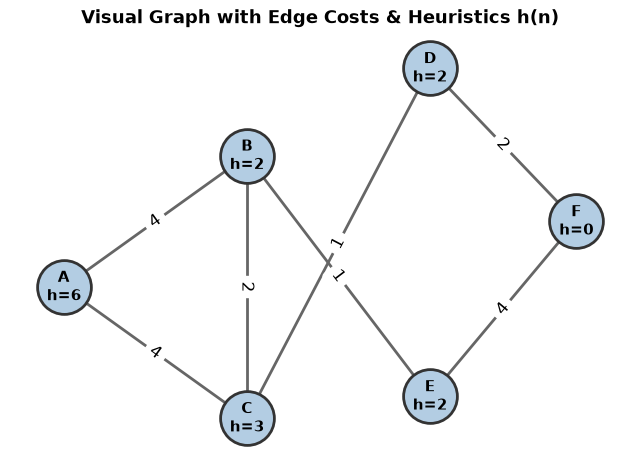

In [2]:
def plot_graph_representations():
    G = nx.Graph()
    for u, neighbors in adj_list.items():
        for v, w in neighbors:
            G.add_edge(u, v, weight=w)

    plt.figure(figsize=(8, 5.5))
    node_labels = {n: f"{n}\nh={h[n]}" for n in nodes}

    nx.draw_networkx_nodes(G, graph_pos, node_color='#b3cde3', node_size=1500, edgecolors='#333333', linewidths=2)
    nx.draw_networkx_labels(G, graph_pos, labels=node_labels, font_size=11, font_weight='bold')
    nx.draw_networkx_edges(G, graph_pos, width=2, edge_color='#666666')
    edge_labels = nx.get_edge_attributes(G, 'weight')
    nx.draw_networkx_edge_labels(G, graph_pos, edge_labels=edge_labels, font_size=12)

    plt.title("Visual Graph with Edge Costs & Heuristics h(n)", fontsize=13, fontweight='bold')
    plt.axis('off')
    plt.show()

plot_graph_representations()

### 3. Implementation of Greedy Best-First Search and A* Search

In [3]:
def get_path_cost(adj, path):
    cost = 0
    for u, v in zip(path[:-1], path[1:]):
        for nbr, w in adj[u]:
            if nbr == v:
                cost += w
                break
    return cost

def best_first_path(adj, h_dict, start='A', goal='F'):
    pq = [(h_dict[start], start, [start])]
    visited = set()
    visit_order = []

    while pq:
        h_val, u, path = heapq.heappop(pq)
        if u in visited:
            continue
        visited.add(u)
        visit_order.append(u)

        if u == goal:
            return path, get_path_cost(adj, path), visit_order

        for v, _ in sorted(adj[u], key=lambda x: x[0]):
            if v not in visited:
                heapq.heappush(pq, (h_dict[v], v, path + [v]))

    return None, 0, visit_order

def astar_path(adj, h_dict, start='A', goal='F'):
    pq = [(h_dict[start], 0, start, [start])]
    g_score = {node: math.inf for node in adj}
    g_score[start] = 0
    visited = set()
    visit_order = []

    while pq:
        f_val, g_val, u, path = heapq.heappop(pq)
        if u in visited:
            continue
        visited.add(u)
        visit_order.append(u)

        if u == goal:
            return path, g_val, visit_order

        for v, weight in sorted(adj[u], key=lambda x: x[0]):
            tentative_g = g_val + weight
            if tentative_g < g_score[v]:
                g_score[v] = tentative_g
                f_val_v = tentative_g + h_dict[v]
                heapq.heappush(pq, (f_val_v, tentative_g, v, path + [v]))

    return None, 0, visit_order

### 4. Running Searches and Comparing Table

In [4]:
bfs_res = best_first_path(adj_list, h, 'A', 'F')
astar_res = astar_path(adj_list, h, 'A', 'F')

print("-" * 75)
print(f"{'Algorithm Name':<28} | {'Path':<20} | {'Edge Count':<10} | {'Total Cost':<10}")
print("-" * 75)
for name, res in [("Best-First Search (Greedy)", bfs_res), ("A* Search", astar_res)]:
    path, cost, _ = res
    print(f"{name:<28} | {' -> '.join(path):<20} | {len(path)-1:<10} | {cost:<10}")
print("-" * 75)

---------------------------------------------------------------------------
Algorithm Name               | Path                 | Edge Count | Total Cost
---------------------------------------------------------------------------
Best-First Search (Greedy)   | A -> B -> E -> F     | 3          | 9         
A* Search                    | A -> C -> D -> F     | 3          | 7         
---------------------------------------------------------------------------


### 5. Overestimation Experiment (Inadmissible Heuristic)

In [5]:
astar_over_res = astar_path(adj_list, h_overestimated, 'A', 'F')
print("=== Heuristic Overestimation Study ===")
print("Original Heuristic Path:    ", " -> ".join(astar_res[0]), "Cost:", astar_res[1])
print("Overestimated Heuristic Path:", " -> ".join(astar_over_res[0]), "Cost:", astar_over_res[1])
print("Note: Overestimating h(C) and h(D) diverts A* to a suboptimal path with cost 9!")

=== Heuristic Overestimation Study ===
Original Heuristic Path:     A -> C -> D -> F Cost: 7
Overestimated Heuristic Path: A -> B -> E -> F Cost: 9
Note: Overestimating h(C) and h(D) diverts A* to a suboptimal path with cost 9!


### 6. Visualizing Discovered Paths in Red

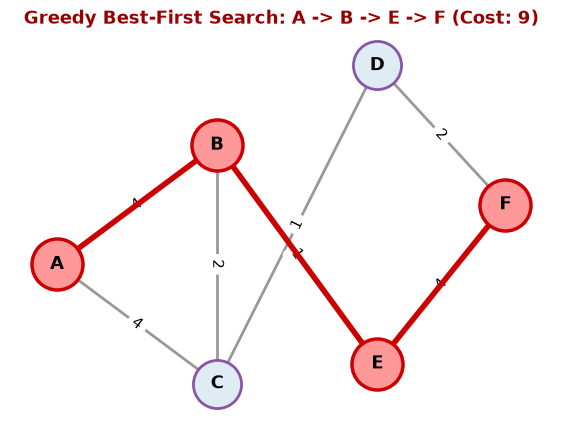

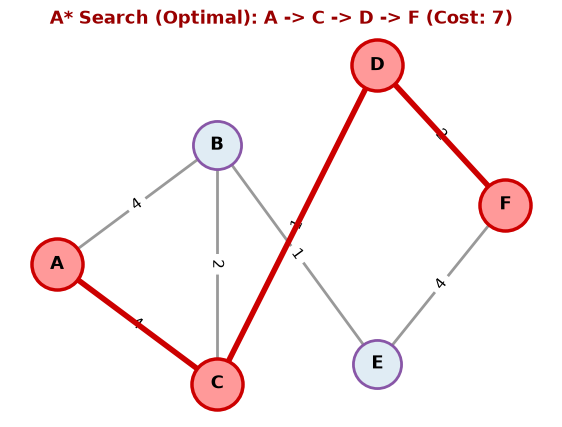

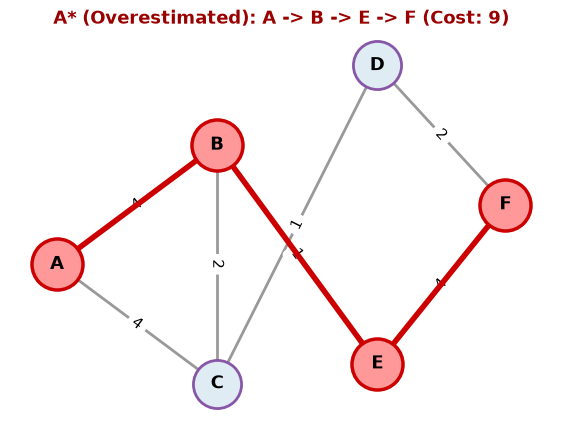

In [6]:
def visualize_search_path(adj, path, title):
    G = nx.Graph()
    for u, neighbors in adj.items():
        for v, w in neighbors:
            G.add_edge(u, v, weight=w)

    path_edges = list(zip(path[:-1], path[1:]))

    plt.figure(figsize=(7, 5))
    nx.draw_networkx_nodes(G, graph_pos, node_color='#e0ecf4', node_size=1200, edgecolors='#8856a7', linewidths=2)
    nx.draw_networkx_labels(G, graph_pos, font_size=13, font_weight='bold')
    nx.draw_networkx_edges(G, graph_pos, width=2, edge_color='#999999')
    edge_labels = nx.get_edge_attributes(G, 'weight')
    nx.draw_networkx_edge_labels(G, graph_pos, edge_labels=edge_labels, font_size=11)

    nx.draw_networkx_nodes(G, graph_pos, nodelist=path, node_color='#ff9999', node_size=1350, edgecolors='#cc0000', linewidths=2.5)
    nx.draw_networkx_edges(G, graph_pos, edgelist=path_edges, width=4, edge_color='#cc0000')

    plt.title(title, fontsize=13, fontweight='bold', color='#990000')
    plt.axis('off')
    plt.show()

visualize_search_path(adj_list, bfs_res[0], f"Greedy Best-First Search: {' -> '.join(bfs_res[0])} (Cost: {bfs_res[1]})")
visualize_search_path(adj_list, astar_res[0], f"A* Search (Optimal): {' -> '.join(astar_res[0])} (Cost: {astar_res[1]})")
visualize_search_path(adj_list, astar_over_res[0], f"A* (Overestimated): {' -> '.join(astar_over_res[0])} (Cost: {astar_over_res[1]})")